# A9 — Learning the Depth Information for Kinect Skeleton Avatars with PyTorch and MLflow

This notebook evaluates deep learning models for predicting Kinect depth values (`z`) from 2D joint coordinates (`x`, `y`).

Tested model families:
- Dense
- Conv1D

The task is formulated as a sequence-to-sequence regression problem:
- **Input per frame:** 13 joints × 2 coordinates = 26 features
- **Target per frame:** 13 joints × z coordinate = 13 values

This notebook follows the Lab 9 instructions by:
- going through the Deep Learning steps
- varying hyperparameters
- using cross-validation
- suggesting the optimal setup
- documenting dead ends
- reporting accuracy in a user-understandable metric
- saving the champion model for reuse
- logging experiments with MLflow

## Imports and shared configuration

In [1]:
from pathlib import Path
import os
import random
import warnings
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv


warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Shared experiment settings
SEQ_LEN = 20
STRIDE = 1
N_SPLITS = 5
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 1e-3

LOSS_NAME = "mse"
DEFAULT_OPTIMIZER = "adam"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep the same path style as your previous notebook
DATA_DIR = Path("../../data/raw/kinect_good_preprocessed")

# Reporting / artifact paths
output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

JOINTS = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

INPUT_FEATURES = [f"{j}_{axis}" for j in JOINTS for axis in ["x", "y"]]
TARGET_FEATURES = [f"{j}_z" for j in JOINTS]

FRAME_COL_CANDIDATES = ["FrameNo", "frame", "frame_no", "Frame", "frameno"]
SEQUENCE_COL_CANDIDATES = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]

# Set this based on your raw z-values
TARGET_UNIT = "meters"

def to_cm(value):
    if TARGET_UNIT == "meters":
        return value * 100.0
    return value

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Input features:", len(INPUT_FEATURES))
print("Target features:", len(TARGET_FEATURES))

/Users/pettergustafsson/study/4DT907/project_dir/ml/models/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.7.1
Device: cpu
Input features: 26
Target features: 13


## MLFlow setup

In [2]:
load_dotenv("../../ml.env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A9_dense_conv1d_depth_regression"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A9_dense_conv1d_depth_regression


## Helper functions

In [4]:
def read_table_file(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    if suffix == ".txt":
        try:
            df = pd.read_csv(path)
            if df.shape[1] > 1:
                return df
        except Exception:
            pass
        return pd.read_csv(path, delim_whitespace=True)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Unsupported file type: {path}")


def find_frame_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in FRAME_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def find_sequence_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in SEQUENCE_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def standardize_joint_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    rename_map = {}
    for col in df.columns:
        normalized = col.strip().lower().replace(" ", "_").replace("-", "_")
        rename_map[col] = normalized
    return df.rename(columns=rename_map)

## Load Kinect movement data

In [5]:
def load_kinect_data(data_dir: Path) -> pd.DataFrame:
    if not data_dir.exists():
        raise FileNotFoundError(
            f"DATA_DIR does not exist: {data_dir}\n"
            "Update DATA_DIR in the config cell to your raw Kinect folder."
        )

    files = []
    for pattern in ["*.csv", "*.tsv", "*.txt", "*.xlsx", "*.xls", "*.parquet"]:
        files.extend(sorted(data_dir.glob(pattern)))

    if not files:
        raise FileNotFoundError(
            f"No supported data files found in {data_dir}.\n"
            "Expected csv, tsv, txt, xlsx, xls, or parquet."
        )

    dfs = []
    for file_path in files:
        df = read_table_file(file_path)
        df = standardize_joint_column_names(df)

        seq_col = find_sequence_col(df)
        if seq_col is None:
            df["sequence_id"] = file_path.stem
        elif seq_col != "sequence_id":
            df = df.rename(columns={seq_col: "sequence_id"})

        frame_col = find_frame_col(df)
        if frame_col is None:
            df["frameno"] = np.arange(len(df))
        elif frame_col != "frameno":
            df = df.rename(columns={frame_col: "frameno"})

        dfs.append(df)

    full_df = pd.concat(dfs, ignore_index=True)
    full_df = full_df.sort_values(["sequence_id", "frameno"]).reset_index(drop=True)
    return full_df

df = load_kinect_data(DATA_DIR)

print("Shape:", df.shape)
print("Columns:", len(df.columns))
display(df.head())

missing_inputs = [c for c in INPUT_FEATURES if c not in df.columns]
missing_targets = [c for c in TARGET_FEATURES if c not in df.columns]

print("Missing input columns:", missing_inputs)
print("Missing target columns:", missing_targets)

assert not missing_inputs, "Missing input columns."
assert not missing_targets, "Missing target columns."

Shape: (24005, 41)
Columns: 41


,frameno,head_x,head_y,head_z,left_shoulder_x,left_shoulder_y,left_shoulder_z,left_elbow_x,left_elbow_y,left_elbow_z,...,right_knee_x,right_knee_y,right_knee_z,left_foot_x,left_foot_y,left_foot_z,right_foot_x,right_foot_y,right_foot_z,sequence_id
0,3,-0.016480,0.77960,0.070646,-0.16221,0.58030,0.047752,-0.23056,0.84519,-0.033909,...,0.13624,-0.51948,0.003528,-0.13975,-0.86193,-0.025068,0.15162,-0.91701,-0.005627,A100_kinect
1,4,-0.016990,0.77937,0.069989,-0.16242,0.58031,0.047168,-0.23050,0.84547,-0.034061,...,0.13663,-0.51921,0.003291,-0.13982,-0.86208,-0.024980,0.15001,-0.91352,-0.001491,A100_kinect
2,5,-0.017345,0.77928,0.069703,-0.16258,0.58039,0.046964,-0.23044,0.84564,-0.034175,...,0.13633,-0.51957,0.003223,-0.13937,-0.86233,-0.024777,0.14981,-0.91385,-0.001252,A100_kinect
3,6,-0.017602,0.77935,0.069520,-0.16276,0.58035,0.046524,-0.23037,0.84598,-0.034318,...,0.13653,-0.51892,0.002961,-0.13907,-0.86225,-0.024431,0.15711,-0.92048,-0.014920,A100_kinect
4,7,-0.017559,0.77938,0.069530,-0.16279,0.58030,0.046288,-0.22906,0.85070,-0.036518,...,0.13662,-0.51940,0.002998,-0.13917,-0.86364,-0.025274,0.15212,-0.91871,-0.004539,A100_kinect


Missing input columns: []
Missing target columns: []


## Build fixed-length sequences

In [8]:
def build_sequences(
    df: pd.DataFrame,
    input_cols,
    target_cols,
    seq_len: int = 20,
    stride: int = 1,
):
    X_list = []
    y_list = []
    seq_ids = []

    clean_df = df.dropna(subset=input_cols + target_cols).copy()

    for seq_id, group in clean_df.groupby("sequence_id"):
        group = group.sort_values("frameno").reset_index(drop=True)

        x_values = group[input_cols].to_numpy(dtype=np.float32)
        y_values = group[target_cols].to_numpy(dtype=np.float32)

        if len(group) < seq_len:
            continue

        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            X_list.append(x_values[start:end])
            y_list.append(y_values[start:end])
            seq_ids.append(seq_id)

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    seq_ids = np.array(seq_ids)

    return X, y, seq_ids

X, y, seq_ids = build_sequences(
    df=df,
    input_cols=INPUT_FEATURES,
    target_cols=TARGET_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("seq_ids shape:", seq_ids.shape)

X shape: (20604, 20, 26)
y shape: (20604, 20, 13)
seq_ids shape: (20604,)


## Inspect target scale

In [7]:
z_summary = df[TARGET_FEATURES].describe().T[["mean", "std", "min", "max"]]
display(z_summary)

print("TARGET_UNIT =", TARGET_UNIT)

,mean,std,min,max
head_z,-0.041466,0.096579,-0.37941,0.188800
left_shoulder_z,-0.037638,0.073275,-0.31771,0.154210
left_elbow_z,-0.147002,0.116080,-0.54195,0.128840
right_shoulder_z,-0.038818,0.078787,-0.33537,0.186630
right_elbow_z,-0.134302,0.123639,-0.56776,0.329820
left_hand_z,-0.239894,0.161802,-0.79979,0.125770
right_hand_z,-0.220100,0.164971,-0.81429,0.464960
left_hip_z,0.046929,0.086418,-0.30135,0.364500
right_hip_z,0.046611,0.088141,-0.32356,0.384430
left_knee_z,-0.136890,0.097322,-0.59866,0.110160


TARGET_UNIT = meters


## Dataset and scaling helpers

In [9]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
    
def fit_scaler_on_training_sequences(X_train):
    scaler = StandardScaler()
    X_train_2d = X_train.reshape(-1, X_train.shape[-1])
    scaler.fit(X_train_2d)
    return scaler


def transform_sequences(X_data, scaler):
    X_2d = X_data.reshape(-1, X_data.shape[-1])
    X_scaled = scaler.transform(X_2d).reshape(X_data.shape).astype(np.float32)
    return X_scaled

## Define Deep Learning models

In [10]:
class DenseDepthRegressor(nn.Module):
    def __init__(self, seq_len, n_features, n_targets, hidden_units=(256, 128), dropout_rate=0.0):
        super().__init__()
        input_dim = seq_len * n_features
        output_dim = seq_len * n_targets

        layers_list = []
        prev_dim = input_dim

        for units in hidden_units:
            layers_list.append(nn.Linear(prev_dim, units))
            layers_list.append(nn.ReLU())
            if dropout_rate > 0:
                layers_list.append(nn.Dropout(dropout_rate))
            prev_dim = units

        layers_list.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers_list)

        self.seq_len = seq_len
        self.n_targets = n_targets

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        out = self.network(x)
        out = out.reshape(batch_size, self.seq_len, self.n_targets)
        return out
    
class Conv1DDepthRegressor(nn.Module):
    def __init__(self, n_features, n_targets, filters=(64, 128), kernel_size=3, dropout_rate=0.0):
        super().__init__()

        conv_layers = []
        in_channels = n_features

        for f in filters:
            conv_layers.append(nn.Conv1d(in_channels, f, kernel_size=kernel_size, padding="same"))
            conv_layers.append(nn.ReLU())
            if dropout_rate > 0:
                conv_layers.append(nn.Dropout(dropout_rate))
            in_channels = f

        self.feature_extractor = nn.Sequential(*conv_layers)
        self.output_layer = nn.Conv1d(in_channels, n_targets, kernel_size=1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.feature_extractor(x)
        x = self.output_layer(x)
        x = x.transpose(1, 2)
        return x
    

def build_model(model_family, config):
    if model_family == "Dense":
        return DenseDepthRegressor(
            seq_len=SEQ_LEN,
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_units=config["hidden_units"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    elif model_family == "Conv1D":
        return Conv1DDepthRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            filters=config["filters"],
            kernel_size=config["kernel_size"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    else:
        raise ValueError(f"Unknown model_family: {model_family}")

## Training and evaluation helpers

In [11]:
def get_optimizer(model, optimizer_name="adam", lr=LEARNING_RATE):
    if optimizer_name.lower() == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name.lower() == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")
    
def evaluate_loss(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    n_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            n_samples += batch_size

    return total_loss / max(n_samples, 1)


def predict_model(model, data_loader):
    model.eval()
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            preds = model(X_batch).cpu().numpy()
            preds_all.append(preds)
            targets_all.append(y_batch.numpy())

    y_pred = np.concatenate(preds_all, axis=0)
    y_true = np.concatenate(targets_all, axis=0)
    return y_true, y_pred


def per_joint_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred), axis=(0, 1))

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
):
    model = model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = get_optimizer(model, optimizer_name=optimizer_name, lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mae": [],
        "val_mae": [],
    }

    best_model_state = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        total_train_mae = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
            n_train += batch_size

        train_loss = total_train_loss / max(n_train, 1)
        train_mae = total_train_mae / max(n_train, 1)

        val_loss = evaluate_loss(model, val_loader, criterion)

        model.eval()
        total_val_mae = 0.0
        n_val = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                preds = model(X_batch)
                batch_size = X_batch.size(0)
                total_val_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
                n_val += batch_size
        val_mae = total_val_mae / max(n_val, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_model_state)
    return model, history, best_val_loss, best_epoch

## Experiment configurations

In [12]:
experiment_configs = [
    {
        "model_family": "Dense",
        "model_variant": "Dense_256_128",
        "hidden_units": (256, 128),
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Dense",
        "model_variant": "Dense_512_256_128_dropout",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.2,
    },
    {
        "model_family": "Conv1D",
        "model_variant": "Conv1D_64_128_k3",
        "filters": (64, 128),
        "kernel_size": 3,
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Conv1D",
        "model_variant": "Conv1D_64_128_128_k5_dropout",
        "filters": (64, 128, 128),
        "kernel_size": 5,
        "dropout_rate": 0.2,
    },
]

experiment_configs

[{'model_family': 'Dense',
  'model_variant': 'Dense_256_128',
  'hidden_units': (256, 128),
  'dropout_rate': 0.0},
 {'model_family': 'Dense',
  'model_variant': 'Dense_512_256_128_dropout',
  'hidden_units': (512, 256, 128),
  'dropout_rate': 0.2},
 {'model_family': 'Conv1D',
  'model_variant': 'Conv1D_64_128_k3',
  'filters': (64, 128),
  'kernel_size': 3,
  'dropout_rate': 0.0},
 {'model_family': 'Conv1D',
  'model_variant': 'Conv1D_64_128_128_k5_dropout',
  'filters': (64, 128, 128),
  'kernel_size': 5,
  'dropout_rate': 0.2}]

## Cross-validation with MLflow logging

In [13]:
def run_cv_experiment(X, y, seq_ids, config):
    gkf = GroupKFold(n_splits=N_SPLITS)

    fold_results = []
    fold_histories = []

    with mlflow.start_run(run_name=config["model_variant"], nested=False):
        mlflow.log_param("model_family", config["model_family"])
        mlflow.log_param("model_variant", config["model_variant"])
        mlflow.log_param("sequence_length", SEQ_LEN)
        mlflow.log_param("stride", STRIDE)
        mlflow.log_param("n_splits", N_SPLITS)
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("patience", PATIENCE)
        mlflow.log_param("learning_rate", LEARNING_RATE)
        mlflow.log_param("optimizer", DEFAULT_OPTIMIZER)
        mlflow.log_param("loss", LOSS_NAME)
        mlflow.log_param("target_unit", TARGET_UNIT)

        for key, value in config.items():
            if key not in ["model_family", "model_variant"]:
                mlflow.log_param(key, str(value))

        for fold_idx, (train_val_idx, test_idx) in enumerate(gkf.split(X, y, groups=seq_ids), start=1):
            X_train_val = X[train_val_idx]
            y_train_val = y[train_val_idx]
            seq_train_val = seq_ids[train_val_idx]

            X_test = X[test_idx]
            y_test = y[test_idx]

            unique_train_sequences = np.unique(seq_train_val)
            train_seq_ids, val_seq_ids = train_test_split(
                unique_train_sequences,
                test_size=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            train_mask = np.isin(seq_train_val, train_seq_ids)
            val_mask = np.isin(seq_train_val, val_seq_ids)

            X_train = X_train_val[train_mask]
            y_train = y_train_val[train_mask]
            X_val = X_train_val[val_mask]
            y_val = y_train_val[val_mask]

            scaler = fit_scaler_on_training_sequences(X_train)
            X_train_scaled = transform_sequences(X_train, scaler)
            X_val_scaled = transform_sequences(X_val, scaler)
            X_test_scaled = transform_sequences(X_test, scaler)

            train_dataset = SequenceDataset(X_train_scaled, y_train)
            val_dataset = SequenceDataset(X_val_scaled, y_val)
            test_dataset = SequenceDataset(X_test_scaled, y_test)

            train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
            val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
            test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

            model = build_model(config["model_family"], config)

            trained_model, history, best_val_loss, best_epoch = train_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                optimizer_name=DEFAULT_OPTIMIZER,
                lr=LEARNING_RATE,
                epochs=EPOCHS,
                patience=PATIENCE,
            )

            y_true, y_pred = predict_model(trained_model, test_loader)

            test_mae = mean_absolute_error(
                y_true.reshape(-1, y_true.shape[-1]),
                y_pred.reshape(-1, y_pred.shape[-1]),
            )
            test_mae_cm = to_cm(test_mae)

            joint_errors = per_joint_mae(y_true, y_pred)
            joint_errors_cm = [to_cm(v) for v in joint_errors]

            mlflow.log_metric(f"fold_{fold_idx}_test_mae", float(test_mae))
            mlflow.log_metric(f"fold_{fold_idx}_test_mae_cm", float(test_mae_cm))
            mlflow.log_metric(f"fold_{fold_idx}_best_val_loss", float(best_val_loss))
            mlflow.log_metric(f"fold_{fold_idx}_best_epoch", int(best_epoch))

            fold_result = {
                "fold": fold_idx,
                "model_family": config["model_family"],
                "model_variant": config["model_variant"],
                "test_mae": float(test_mae),
                "test_mae_cm": float(test_mae_cm),
                "best_val_loss": float(best_val_loss),
                "best_epoch": int(best_epoch),
                "n_train_sequences": int(len(X_train)),
                "n_val_sequences": int(len(X_val)),
                "n_test_sequences": int(len(X_test)),
                "joint_mae_cm": joint_errors_cm,
            }

            fold_results.append(fold_result)
            fold_histories.append(history)

        fold_df = pd.DataFrame(fold_results)

        mlflow.log_metric("mean_test_mae", float(fold_df["test_mae"].mean()))
        mlflow.log_metric("std_test_mae", float(fold_df["test_mae"].std()))
        mlflow.log_metric("mean_test_mae_cm", float(fold_df["test_mae_cm"].mean()))
        mlflow.log_metric("std_test_mae_cm", float(fold_df["test_mae_cm"].std()))
        mlflow.log_metric("mean_best_val_loss", float(fold_df["best_val_loss"].mean()))
        mlflow.log_metric("mean_best_epoch", float(fold_df["best_epoch"].mean()))

    return fold_results, fold_histories

## Run all experiments

In [14]:
all_fold_results = []
all_histories = {}

for config in experiment_configs:
    print(f"Running {config['model_variant']} ...")
    fold_results, fold_histories = run_cv_experiment(X, y, seq_ids, config)
    all_fold_results.extend(fold_results)
    all_histories[config["model_variant"]] = fold_histories

results_folds = pd.DataFrame(all_fold_results)
display(results_folds.head())

Running Dense_256_128 ...
🏃 View run Dense_256_128 at: https://172.27.62.170:5001/#/experiments/22/runs/7705a82b2cd143c9bc78b544302d3034
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_512_256_128_dropout ...
🏃 View run Dense_512_256_128_dropout at: https://172.27.62.170:5001/#/experiments/22/runs/0aa3ff23cbcb408c8b03858e1f88d4a6
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Conv1D_64_128_k3 ...
🏃 View run Conv1D_64_128_k3 at: https://172.27.62.170:5001/#/experiments/22/runs/456cef825b8045b68eeca3a9afb58160
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Conv1D_64_128_128_k5_dropout ...
🏃 View run Conv1D_64_128_128_k5_dropout at: https://172.27.62.170:5001/#/experiments/22/runs/e481bc2758d74ad9a87d196c16d3336d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22


,fold,model_family,model_variant,test_mae,test_mae_cm,best_val_loss,best_epoch,n_train_sequences,n_val_sequences,n_test_sequences,joint_mae_cm
0,1,Dense,Dense_256_128,0.043135,4.313509,0.002625,8,14907,1566,4131,"[4.589501395821571, 3.93165722489357, 4.500273..."
1,2,Dense,Dense_256_128,0.039552,3.955186,0.002510,4,14923,1552,4129,"[3.222743421792984, 3.100852854549885, 4.88814..."
2,3,Dense,Dense_256_128,0.034101,3.410101,0.003060,2,14641,1839,4124,"[3.2268475741147995, 2.5791052728891373, 3.320..."
3,4,Dense,Dense_256_128,0.032380,3.238042,0.004106,15,15121,1359,4124,"[3.1766723841428757, 2.6383450254797935, 4.228..."
4,5,Dense,Dense_256_128,0.038818,3.881849,0.004228,8,14535,1973,4096,"[3.840022161602974, 3.1473059207201004, 3.8874..."


## Results and select the champion

In [15]:
results_summary = (
    results_folds
    .groupby(["model_family", "model_variant"], as_index=False)
    .agg(
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mae_cm=("test_mae_cm", "mean"),
        std_test_mae_cm=("test_mae_cm", "std"),
        mean_best_val_loss=("best_val_loss", "mean"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values("mean_test_mae_cm", ascending=True)
    .reset_index(drop=True)
)

display(results_summary)

,model_family,model_variant,mean_test_mae,std_test_mae,mean_test_mae_cm,std_test_mae_cm,mean_best_val_loss,mean_best_epoch
0,Conv1D,Conv1D_64_128_128_k5_dropout,0.036797,0.005720,3.679668,0.571959,0.003404,7.0
1,Dense,Dense_256_128,0.037597,0.004342,3.759737,0.434219,0.003306,7.4
2,Dense,Dense_512_256_128_dropout,0.038346,0.004636,3.834583,0.463646,0.003292,16.2
3,Conv1D,Conv1D_64_128_k3,0.039309,0.006231,3.930896,0.623086,0.003250,16.4


In [16]:
champion_row = results_summary.iloc[0]
champion_variant = champion_row["model_variant"]
champion_family = champion_row["model_family"]

print("Champion model:", champion_variant)
print("Champion family:", champion_family)
print(f"Mean CV test MAE: {champion_row['mean_test_mae']:.6f}")
print(f"Mean CV test MAE in cm: {champion_row['mean_test_mae_cm']:.3f} cm")
print(f"Std CV test MAE in cm: {champion_row['std_test_mae_cm']:.3f} cm")

Champion model: Conv1D_64_128_128_k5_dropout
Champion family: Conv1D
Mean CV test MAE: 0.036797
Mean CV test MAE in cm: 3.680 cm
Std CV test MAE in cm: 0.572 cm


## Plot training curves for the champion

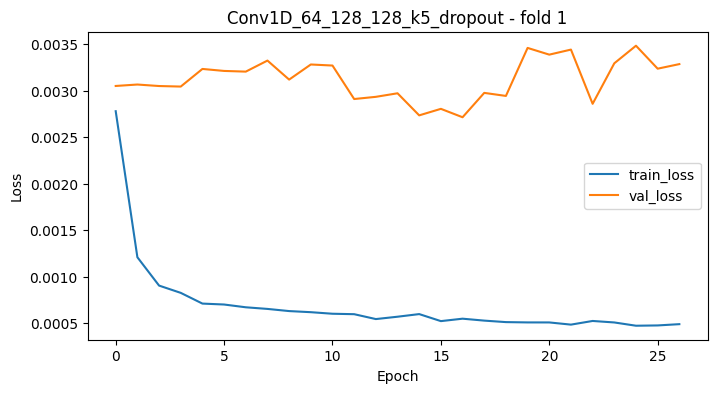

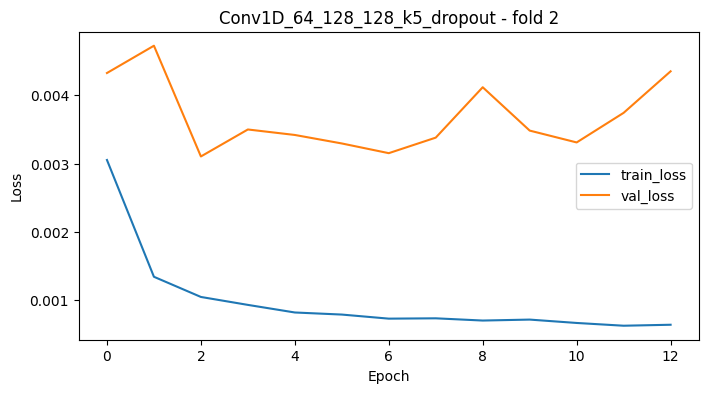

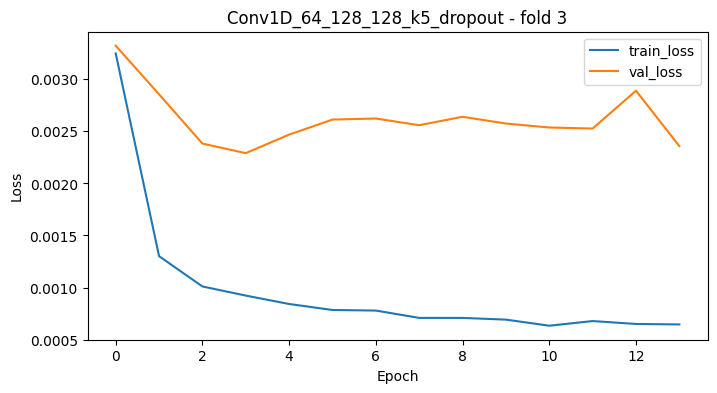

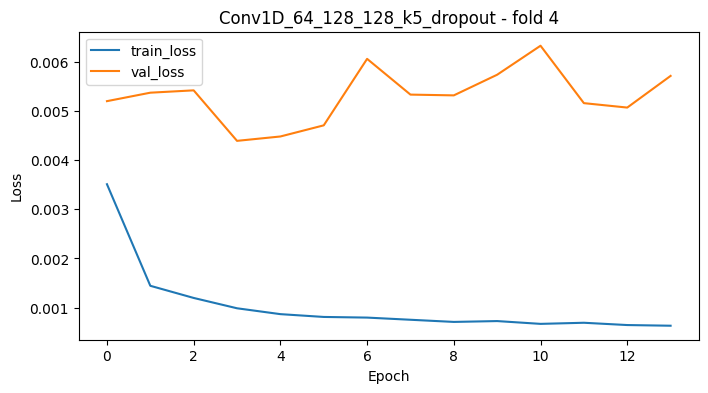

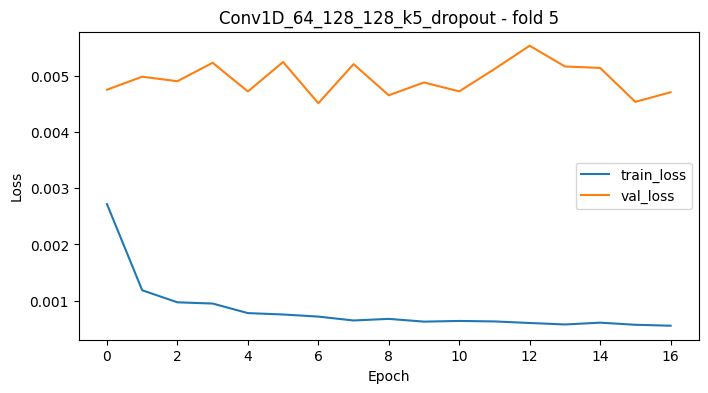

In [17]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

champion_histories = all_histories[champion_variant]
for fold_idx, hist in enumerate(champion_histories, start=1):
    plot_history(hist, f"{champion_variant} - fold {fold_idx}")

## Per-joint evaluation in centimeters

,joint,mean_error_cm,std_error_cm
1,left_shoulder,2.941954,0.608415
7,left_hip,3.043808,0.364607
8,right_hip,3.054868,0.335379
12,right_foot,3.149496,0.717339
3,right_shoulder,3.153361,0.692214
11,left_foot,3.237785,0.627641
10,right_knee,3.294572,0.734991
9,left_knee,3.320874,0.656110
0,head,3.590142,0.735373
2,left_elbow,3.992826,0.534790


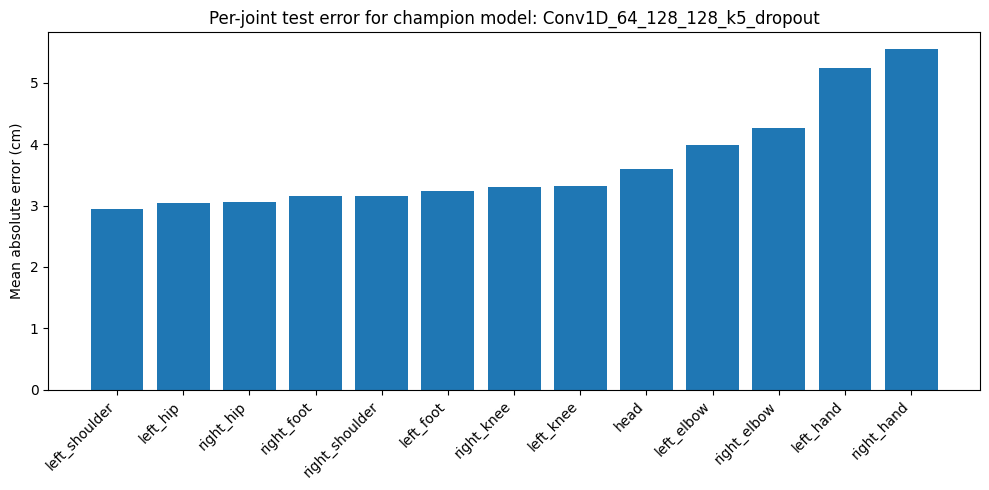

In [18]:
champion_fold_df = results_folds[results_folds["model_variant"] == champion_variant].copy()
joint_mae_matrix = np.array(champion_fold_df["joint_mae_cm"].tolist())

joint_summary = pd.DataFrame({
    "joint": JOINTS,
    "mean_error_cm": joint_mae_matrix.mean(axis=0),
    "std_error_cm": joint_mae_matrix.std(axis=0),
}).sort_values("mean_error_cm", ascending=True)

display(joint_summary)

plt.figure(figsize=(10, 5))
plt.bar(joint_summary["joint"], joint_summary["mean_error_cm"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Mean absolute error (cm)")
plt.title(f"Per-joint test error for champion model: {champion_variant}")
plt.tight_layout()
plt.show()

## Save result tables

In [19]:
fold_results_path = output_dir / "A9_dense_conv1d_pytorch_cv_folds.csv"
summary_results_path = output_dir / "A9_dense_conv1d_pytorch_cv_summary.csv"
joint_results_path = output_dir / "A9_dense_conv1d_pytorch_joint_summary.csv"

results_folds.to_csv(fold_results_path, index=False)
results_summary.to_csv(summary_results_path, index=False)
joint_summary.to_csv(joint_results_path, index=False)

print(f"Saved fold results to: {fold_results_path}")
print(f"Saved summary results to: {summary_results_path}")
print(f"Saved joint summary to: {joint_results_path}")

Saved fold results to: reporting/results/A9_dense_conv1d_pytorch_cv_folds.csv
Saved summary results to: reporting/results/A9_dense_conv1d_pytorch_cv_summary.csv
Saved joint summary to: reporting/results/A9_dense_conv1d_pytorch_joint_summary.csv


## Retrain the champion model on almost all data

In [21]:
champion_config = next(cfg for cfg in experiment_configs if cfg["model_variant"] == champion_variant)

unique_seq_ids = np.unique(seq_ids)
train_seq_ids, val_seq_ids = train_test_split(
    unique_seq_ids,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

train_mask = np.isin(seq_ids, train_seq_ids)
val_mask = np.isin(seq_ids, val_seq_ids)

X_train_final = X[train_mask]
y_train_final = y[train_mask]
X_val_final = X[val_mask]
y_val_final = y[val_mask]

final_scaler = fit_scaler_on_training_sequences(X_train_final)
X_train_final_scaled = transform_sequences(X_train_final, final_scaler)
X_val_final_scaled = transform_sequences(X_val_final, final_scaler)

train_dataset_final = SequenceDataset(X_train_final_scaled, y_train_final)
val_dataset_final = SequenceDataset(X_val_final_scaled, y_val_final)

train_loader_final = DataLoader(train_dataset_final, batch_size=BATCH_SIZE, shuffle=True)
val_loader_final = DataLoader(val_dataset_final, batch_size=BATCH_SIZE, shuffle=False)

final_model = build_model(champion_family, champion_config)

In [22]:
with mlflow.start_run(run_name=f"{champion_variant}_final", nested=False):
    mlflow.log_param("final_model_family", champion_family)
    mlflow.log_param("final_model_variant", champion_variant)

    final_model, final_history, final_best_val_loss, final_best_epoch = train_model(
        model=final_model,
        train_loader=train_loader_final,
        val_loader=val_loader_final,
        optimizer_name=DEFAULT_OPTIMIZER,
        lr=LEARNING_RATE,
        epochs=EPOCHS,
        patience=PATIENCE,
    )

    mlflow.log_metric("final_best_val_loss", float(final_best_val_loss))
    mlflow.log_metric("final_best_epoch", int(final_best_epoch))

    final_model_path = artifact_dir / "A9_champion_model.pt"
    final_scaler_path = artifact_dir / "A9_champion_scaler.npz"
    final_metadata_path = artifact_dir / "A9_champion_metadata.json"

    torch.save(final_model.state_dict(), final_model_path)

    np.savez(
        final_scaler_path,
        mean=final_scaler.mean_,
        scale=final_scaler.scale_,
    )

    metadata = {
        "model_family": champion_family,
        "model_variant": champion_variant,
        "sequence_length": SEQ_LEN,
        "input_features": INPUT_FEATURES,
        "target_features": TARGET_FEATURES,
        "target_unit": TARGET_UNIT,
        "mean_cv_test_mae": float(champion_row["mean_test_mae"]),
        "mean_cv_test_mae_cm": float(champion_row["mean_test_mae_cm"]),
        "std_cv_test_mae_cm": float(champion_row["std_test_mae_cm"]),
        "best_epoch_final": int(final_best_epoch),
        "config": {k: list(v) if isinstance(v, tuple) else v for k, v in champion_config.items()},
    }

    with open(final_metadata_path, "w") as f:
        json.dump(metadata, f, indent=2)

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_metadata_path))

print("Saved champion model to:", final_model_path)
print("Saved scaler to:", final_scaler_path)
print("Saved metadata to:", final_metadata_path)

🏃 View run Conv1D_64_128_128_k5_dropout_final at: https://172.27.62.170:5001/#/experiments/22/runs/9dd57e89f65b455c843c0573f9c4e7e1
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Saved champion model to: reporting/artifacts/A9_champion_model.pt
Saved scaler to: reporting/artifacts/A9_champion_scaler.npz
Saved metadata to: reporting/artifacts/A9_champion_metadata.json


## Load and reuse the champion model

In [23]:
def load_saved_scaler(npz_path):
    data = np.load(npz_path)
    scaler = StandardScaler()
    scaler.mean_ = data["mean"]
    scaler.scale_ = data["scale"]
    scaler.var_ = scaler.scale_ ** 2
    scaler.n_features_in_ = len(scaler.mean_)
    return scaler

with open(final_metadata_path, "r") as f:
    loaded_meta = json.load(f)

loaded_config = loaded_meta["config"]
if "hidden_units" in loaded_config and isinstance(loaded_config["hidden_units"], list):
    loaded_config["hidden_units"] = tuple(loaded_config["hidden_units"])
if "filters" in loaded_config and isinstance(loaded_config["filters"], list):
    loaded_config["filters"] = tuple(loaded_config["filters"])

loaded_model = build_model(loaded_meta["model_family"], loaded_config)
loaded_model.load_state_dict(torch.load(final_model_path, map_location=DEVICE))
loaded_model.to(DEVICE)
loaded_model.eval()

loaded_scaler = load_saved_scaler(final_scaler_path)

print("Loaded model:", loaded_meta["model_variant"])

X_sample = X[:5]
X_sample_scaled = transform_sequences(X_sample, loaded_scaler)

sample_ds = SequenceDataset(X_sample_scaled, y[:5])
sample_loader = DataLoader(sample_ds, batch_size=5, shuffle=False)

y_true_sample, y_pred_sample = predict_model(loaded_model, sample_loader)

sample_mae = mean_absolute_error(
    y_true_sample.reshape(-1, y_true_sample.shape[-1]),
    y_pred_sample.reshape(-1, y_pred_sample.shape[-1]),
)

print("Sample MAE:", sample_mae)
print("Sample MAE (cm):", to_cm(sample_mae))

Loaded model: Conv1D_64_128_128_k5_dropout
Sample MAE: 0.013738265
Sample MAE (cm): 1.373826526105404


In [30]:

class MoveNetToKinectWrapper(mlflow.pyfunc.PythonModel):
    """
    Wrapper for predicting Kinect 3D coordinates from a 2D Kinect / MoveNet-style file.

    Input:
        - path to csv/tsv/txt/xlsx/parquet
        - pandas DataFrame
        - numpy array of shape (n_frames, 26)

    Output:
        pandas DataFrame with:
        - sequence_id
        - frameno
        - joint_x
        - joint_y
        - predicted joint_z
    """

    DEFAULT_JOINTS = [
        "head",
        "left_shoulder",
        "left_elbow",
        "right_shoulder",
        "right_elbow",
        "left_hand",
        "right_hand",
        "left_hip",
        "right_hip",
        "left_knee",
        "right_knee",
        "left_foot",
        "right_foot",
    ]

    FRAME_COL_CANDIDATES = ["frameno", "FrameNo", "frame", "frame_no", "Frame"]
    SEQUENCE_COL_CANDIDATES = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]

    def __init__(
        self,
        model_state_path=None,
        scaler_path=None,
        metadata_path=None,
        device=None,
        seq_len=None,
        stride=1,
        batch_size=256,
    ):
        self.model_state_path = model_state_path
        self.scaler_path = scaler_path
        self.metadata_path = metadata_path

        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.seq_len = seq_len
        self.stride = stride
        self.batch_size = batch_size

        self.model = None
        self.scaler = None
        self.metadata = None

        self.joints = self.DEFAULT_JOINTS
        self.input_features = [f"{j}_{axis}" for j in self.joints for axis in ["x", "y"]]
        self.target_features = [f"{j}_z" for j in self.joints]

        if model_state_path is not None and scaler_path is not None and metadata_path is not None:
            self._load_from_paths(model_state_path, scaler_path, metadata_path)

    # Required by mlflow.pyfunc.log_model(...)
    def load_context(self, context):
        self._load_from_paths(
            model_state_path=context.artifacts["model_state"],
            scaler_path=context.artifacts["scaler"],
            metadata_path=context.artifacts["metadata"],
        )

    def _load_from_paths(self, model_state_path, scaler_path, metadata_path):
        model_state_path = Path(model_state_path)
        scaler_path = Path(scaler_path)
        metadata_path = Path(metadata_path)

        with open(metadata_path, "r") as f:
            self.metadata = json.load(f)

        self.seq_len = int(self.metadata.get("sequence_length", self.seq_len or 20))
        self.input_features = self.metadata.get("input_features", self.input_features)
        self.target_features = self.metadata.get("target_features", self.target_features)

        self.joints = [c.replace("_z", "") for c in self.target_features]

        config = self.metadata.get("config", {})
        filters = tuple(config.get("filters", (64, 128)))
        kernel_size = int(config.get("kernel_size", 3))
        dropout_rate = float(config.get("dropout_rate", 0.0))

        self.model = Conv1DDepthRegressor(
            n_features=len(self.input_features),
            n_targets=len(self.target_features),
            filters=filters,
            kernel_size=kernel_size,
            dropout_rate=dropout_rate,
        )

        state_dict = torch.load(model_state_path, map_location=self.device)
        self.model.load_state_dict(state_dict)
        self.model.to(self.device)
        self.model.eval()

        self.scaler = self._load_saved_scaler(scaler_path)

    @staticmethod
    def _load_saved_scaler(npz_path):
        data = np.load(npz_path)

        scaler = StandardScaler()
        scaler.mean_ = data["mean"]
        scaler.scale_ = data["scale"]
        scaler.var_ = scaler.scale_ ** 2
        scaler.n_features_in_ = len(scaler.mean_)

        return scaler

    def predict(self, context=None, model_input=None, params=None):
        """
        Supports both:

            wrapper.predict("file.csv")

        and MLflow pyfunc:

            loaded_model.predict(dataframe)
        """

        if model_input is None:
            input_data = context
        else:
            input_data = model_input

        if self.model is None or self.scaler is None:
            raise RuntimeError(
                "Model is not loaded. Either pass artifact paths to the constructor "
                "or load the wrapper through MLflow."
            )

        df = self._to_dataframe(input_data)
        df = self._standardize_column_names(df)
        df = self._ensure_sequence_and_frame_columns(df)
        self._validate_input_columns(df)

        output_parts = []

        for sequence_id, group in df.groupby("sequence_id", sort=False):
            group = group.sort_values("frameno").reset_index(drop=True)

            xy = group[self.input_features].to_numpy(dtype=np.float32)
            z_pred = self._predict_single_sequence(xy)

            out = pd.DataFrame()
            out["sequence_id"] = sequence_id
            out["frameno"] = group["frameno"].to_numpy()

            for joint in self.joints:
                out[f"{joint}_x"] = group[f"{joint}_x"].to_numpy()
                out[f"{joint}_y"] = group[f"{joint}_y"].to_numpy()

            for idx, target_col in enumerate(self.target_features):
                out[target_col] = z_pred[:, idx]

            output_parts.append(out)

        return pd.concat(output_parts, ignore_index=True)

    def _predict_single_sequence(self, xy):
        n_frames = xy.shape[0]

        if n_frames == 0:
            raise ValueError("Input sequence has no frames.")

        if n_frames < self.seq_len:
            pad_len = self.seq_len - n_frames
            pad_values = np.repeat(xy[-1:, :], pad_len, axis=0)
            padded_xy = np.vstack([xy, pad_values])
            starts = [0]
        else:
            padded_xy = xy
            starts = list(range(0, n_frames - self.seq_len + 1, self.stride))

            final_start = n_frames - self.seq_len
            if starts[-1] != final_start:
                starts.append(final_start)

        windows = np.stack(
            [padded_xy[start:start + self.seq_len] for start in starts],
            axis=0,
        ).astype(np.float32)

        windows_scaled = self.scaler.transform(
            windows.reshape(-1, windows.shape[-1])
        ).reshape(windows.shape).astype(np.float32)

        preds = []

        with torch.no_grad():
            for batch_start in range(0, len(windows_scaled), self.batch_size):
                batch = windows_scaled[batch_start:batch_start + self.batch_size]
                batch_tensor = torch.tensor(batch, dtype=torch.float32, device=self.device)
                batch_pred = self.model(batch_tensor).cpu().numpy()
                preds.append(batch_pred)

        preds = np.concatenate(preds, axis=0)

        z_sum = np.zeros((len(padded_xy), len(self.target_features)), dtype=np.float32)
        z_count = np.zeros((len(padded_xy), 1), dtype=np.float32)

        for window_idx, start in enumerate(starts):
            end = start + self.seq_len
            z_sum[start:end] += preds[window_idx]
            z_count[start:end] += 1.0

        z_avg = z_sum / np.maximum(z_count, 1.0)

        return z_avg[:n_frames]

    def _to_dataframe(self, input_data):
        if isinstance(input_data, pd.DataFrame):
            return input_data.copy()

        if isinstance(input_data, np.ndarray):
            if input_data.ndim != 2:
                raise ValueError(
                    f"Expected numpy input with shape (n_frames, n_features), got {input_data.shape}."
                )

            if input_data.shape[1] != len(self.input_features):
                raise ValueError(
                    f"Expected {len(self.input_features)} features, got {input_data.shape[1]}."
                )

            return pd.DataFrame(input_data, columns=self.input_features)

        if isinstance(input_data, (str, Path)):
            return self._read_table_file(Path(input_data))

        raise TypeError(
            "Unsupported input type. Use a file path, pandas DataFrame, or numpy array."
        )

    @staticmethod
    def _read_table_file(path):
        suffix = path.suffix.lower()

        if suffix == ".csv":
            return pd.read_csv(path)

        if suffix == ".tsv":
            return pd.read_csv(path, sep="\t")

        if suffix == ".txt":
            try:
                df = pd.read_csv(path)
                if df.shape[1] > 1:
                    return df
            except Exception:
                pass
            return pd.read_csv(path, delim_whitespace=True)

        if suffix in [".xlsx", ".xls"]:
            return pd.read_excel(path)

        if suffix == ".parquet":
            return pd.read_parquet(path)

        raise ValueError(f"Unsupported file type: {path}")

    @staticmethod
    def _standardize_column_names(df):
        rename_map = {}
        for col in df.columns:
            rename_map[col] = col.strip().lower().replace(" ", "_").replace("-", "_")
        return df.rename(columns=rename_map)

    def _ensure_sequence_and_frame_columns(self, df):
        df = df.copy()

        lower_map = {c.lower(): c for c in df.columns}

        sequence_col = None
        for candidate in self.SEQUENCE_COL_CANDIDATES:
            if candidate.lower() in lower_map:
                sequence_col = lower_map[candidate.lower()]
                break

        frame_col = None
        for candidate in self.FRAME_COL_CANDIDATES:
            if candidate.lower() in lower_map:
                frame_col = lower_map[candidate.lower()]
                break

        if sequence_col is None:
            df["sequence_id"] = "sequence_0"
        elif sequence_col != "sequence_id":
            df = df.rename(columns={sequence_col: "sequence_id"})

        if frame_col is None:
            df["frameno"] = np.arange(len(df))
        elif frame_col != "frameno":
            df = df.rename(columns={frame_col: "frameno"})

        return df

    def _validate_input_columns(self, df):
        missing = [col for col in self.input_features if col not in df.columns]

        if missing:
            raise ValueError(
                "Input file is missing required 2D columns:\n"
                f"{missing}\n\n"
                "Expected columns like: head_x, head_y, left_shoulder_x, left_shoulder_y, ..."
            )

/Users/pettergustafsson/study/4DT907/project_dir/ml/models/venv/lib/python3.11/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [31]:
artifacts = {
    "model_state": "reporting/artifacts/A9_champion_model.pt",
    "scaler": "reporting/artifacts/A9_champion_scaler.npz",
    "metadata": "reporting/artifacts/A9_champion_metadata.json",
}

with mlflow.start_run(run_name="log_a9_kinect2d_to_kinect_3d_wrapper") as run:
    mlflow.pyfunc.log_model(
        name="model",
        python_model=MoveNetToKinectWrapper(),
        artifacts=artifacts,
        pip_requirements=[
            "mlflow",
            "torch",
            "numpy",
            "pandas",
            "scikit-learn",
        ],
    )
print("logged")

🏃 View run log_a9_kinect2d_to_kinect_3d_wrapper at: https://172.27.62.170:5001/#/experiments/22/runs/dc16179fb7dd49008370f573b29feda4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
logged


In [32]:
# Load model from mlflow
model_uri = "models:/m-ac1c51060337435c82dce450657cd0dc"
loaded_model = mlflow.pyfunc.load_model(model_uri)

In [34]:
# Make prediction.
a1_kinect = pd.read_csv("../../data/raw/kinect_good_preprocessed/A1_kinect.csv")
a1_kinect = a1_kinect.loc[:, ~a1_kinect.columns.str.contains("_z")]
a1_kinect

,FrameNo,head_x,head_y,left_shoulder_x,left_shoulder_y,left_elbow_x,left_elbow_y,right_shoulder_x,right_shoulder_y,right_elbow_x,...,right_hip_x,right_hip_y,left_knee_x,left_knee_y,right_knee_x,right_knee_y,left_foot_x,left_foot_y,right_foot_x,right_foot_y
0,68,0.012479,0.77345,-0.13806,0.56134,-0.23846,0.78626,0.16386,0.53453,0.27576,...,0.070990,0.050062,-0.12024,-0.31613,0.10949,-0.32352,-0.13160,-0.73613,0.13035,-0.74466
1,69,0.012189,0.77359,-0.13808,0.56113,-0.23875,0.78576,0.16382,0.53451,0.27553,...,0.071481,0.049983,-0.11961,-0.31636,0.11010,-0.32371,-0.13135,-0.73634,0.13078,-0.74484
2,70,0.011877,0.77387,-0.13805,0.56091,-0.23911,0.78529,0.16376,0.53471,0.27530,...,0.072057,0.049890,-0.11884,-0.31667,0.11070,-0.32399,-0.13110,-0.73665,0.13120,-0.74506
3,71,0.011558,0.77405,-0.13800,0.56081,-0.23967,0.78489,0.16366,0.53504,0.27518,...,0.072543,0.049759,-0.11805,-0.31707,0.11128,-0.32436,-0.13102,-0.73711,0.13164,-0.74529
4,72,0.011211,0.77415,-0.13795,0.56081,-0.24036,0.78463,0.16347,0.53560,0.27516,...,0.072987,0.049613,-0.11727,-0.31750,0.11181,-0.32480,-0.13096,-0.73750,0.13212,-0.74567
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,175,0.012492,0.76850,-0.13829,0.54733,-0.25480,0.76380,0.16791,0.53724,0.28812,...,0.084054,0.043623,-0.10902,-0.32589,0.12176,-0.33224,-0.13167,-0.74733,0.13331,-0.74467
108,176,0.012824,0.77170,-0.13791,0.55032,-0.25453,0.76673,0.16825,0.54024,0.28834,...,0.084621,0.046992,-0.10871,-0.32251,0.12149,-0.32896,-0.13152,-0.74536,0.13363,-0.74340
109,177,0.013109,0.77451,-0.13749,0.55184,-0.25424,0.76846,0.16856,0.54178,0.28834,...,0.085045,0.049722,-0.10856,-0.31974,0.12137,-0.32613,-0.13133,-0.74335,0.13394,-0.74212
110,178,0.013396,0.77710,-0.13700,0.55338,-0.25386,0.77014,0.16889,0.54327,0.28835,...,0.085366,0.052034,-0.10855,-0.31732,0.12126,-0.32370,-0.13106,-0.74131,0.13423,-0.74063


In [39]:
predictions = loaded_model.predict(a1_kinect)
predictions = predictions.reindex(sorted(predictions.columns), axis=1)
predictions


,frameno,head_x,head_y,head_z,left_elbow_x,left_elbow_y,left_elbow_z,left_foot_x,left_foot_y,left_foot_z,...,right_hip_x,right_hip_y,right_hip_z,right_knee_x,right_knee_y,right_knee_z,right_shoulder_x,right_shoulder_y,right_shoulder_z,sequence_id
0,68,0.012479,0.77345,0.027042,-0.23846,0.78626,-0.026799,-0.13160,-0.73613,-0.058306,...,0.070990,0.050062,-0.009331,0.10949,-0.32352,-0.058212,0.16386,0.53453,0.020242,NaN
1,69,0.012189,0.77359,0.024411,-0.23875,0.78576,-0.028146,-0.13135,-0.73634,-0.056904,...,0.071481,0.049983,-0.008729,0.11010,-0.32371,-0.060292,0.16382,0.53451,0.018108,NaN
2,70,0.011877,0.77387,0.022491,-0.23911,0.78529,-0.030476,-0.13110,-0.73665,-0.056022,...,0.072057,0.049890,-0.006570,0.11070,-0.32399,-0.061210,0.16376,0.53471,0.017403,NaN
3,71,0.011558,0.77405,0.020620,-0.23967,0.78489,-0.032122,-0.13102,-0.73711,-0.054888,...,0.072543,0.049759,-0.005214,0.11128,-0.32436,-0.060973,0.16366,0.53504,0.016916,NaN
4,72,0.011211,0.77415,0.019115,-0.24036,0.78463,-0.033628,-0.13096,-0.73750,-0.054062,...,0.072987,0.049613,-0.004449,0.11181,-0.32480,-0.060649,0.16347,0.53560,0.016386,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,175,0.012492,0.76850,-0.002262,-0.25480,0.76380,-0.060995,-0.13167,-0.74733,-0.053259,...,0.084054,0.043623,-0.029036,0.12176,-0.33224,-0.065728,0.16791,0.53724,0.002310,NaN
108,176,0.012824,0.77170,-0.000059,-0.25453,0.76673,-0.058508,-0.13152,-0.74536,-0.052347,...,0.084621,0.046992,-0.028210,0.12149,-0.32896,-0.065002,0.16825,0.54024,0.004039,NaN
109,177,0.013109,0.77451,0.003150,-0.25424,0.76846,-0.055685,-0.13133,-0.74335,-0.051317,...,0.085045,0.049722,-0.027030,0.12137,-0.32613,-0.064373,0.16856,0.54178,0.006433,NaN
110,178,0.013396,0.77710,0.007511,-0.25386,0.77014,-0.052772,-0.13106,-0.74131,-0.049595,...,0.085366,0.052034,-0.025300,0.12126,-0.32370,-0.063565,0.16889,0.54327,0.009071,NaN


## Dead ends and findings

In [43]:
predictions.to_csv("test.csv", index=False)

In [44]:
best_row = results_summary.iloc[0]
worst_row = results_summary.iloc[-1]

print("Best model:")
display(best_row)

print("Worst model:")
display(worst_row)

Best model:


model_family                                Conv1D
model_variant         Conv1D_64_128_128_k5_dropout
mean_test_mae                             0.036797
std_test_mae                               0.00572
mean_test_mae_cm                          3.679668
std_test_mae_cm                           0.571959
mean_best_val_loss                        0.003404
mean_best_epoch                                7.0
Name: 0, dtype: object

Worst model:


model_family                    Conv1D
model_variant         Conv1D_64_128_k3
mean_test_mae                 0.039309
std_test_mae                  0.006231
mean_test_mae_cm              3.930896
std_test_mae_cm               0.623086
mean_best_val_loss             0.00325
mean_best_epoch                   16.4
Name: 3, dtype: object